# 스트리밍 알고리즘 2종 비교 실험

## 1. 데이터 경로와 반복 횟수

In [3]:
from pathlib import Path

DATA_PATH = Path("/content/Online Retail.xlsx")
REPEATS = 3

if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Colab 파일 패널에 데이터를 업로드하세요. 경로는 {DATA_PATH}입니다.")

## 2. 알고리즘 구현

In [5]:
from __future__ import annotations

import hashlib
import math
import platform
import random
import statistics
import struct
import sys
import tempfile
from array import array
from collections import Counter
from datetime import datetime, timedelta
from pathlib import Path
from time import perf_counter
from xml.etree import ElementTree as ET
from zipfile import ZipFile


class BloomFilter:

    def __init__(self, m, k):
        self.m, self.k = m, k
        self.bits = bytearray((m + 7) // 8)

    def positions(self, key):
        first, step = struct.unpack("<QQ", hashlib.blake2b(key, digest_size=16).digest())
        step |= 1
        return ((first + i * step) % self.m for i in range(self.k))

    def add(self, key):
        for index in self.positions(key):
            self.bits[index >> 3] |= 1 << (index & 7)

    def contains(self, key):
        return all(self.bits[index >> 3] & (1 << (index & 7))
                   for index in self.positions(key))


class CountMinSketch:

    def __init__(self, width, depth):
        self.width, self.depth = width, depth
        self.counts = array("I", [0]) * (width * depth)

    def positions(self, key):
        hashes = struct.unpack("<16I", hashlib.blake2b(key).digest())
        return (row * self.width + hashes[row] % self.width
                for row in range(self.depth))

    def add(self, key):
        for index in self.positions(key):
            self.counts[index] += 1

    def estimate(self, key):
        return min(self.counts[index] for index in self.positions(key))

## 3. XLSX 순차 읽기와 성능 측정

In [9]:
NS = "{http://schemas.openxmlformats.org/spreadsheetml/2006/main}"


def xml_records(source, record, parent):
    container = None
    for event, element in ET.iterparse(source, events=("start", "end")):
        if event == "start" and element.tag == NS + parent:
            container = element
        elif event == "end" and element.tag == NS + record:
            yield element
            container.remove(element)


def excel_rows(path):
    with ZipFile(path) as book:
        strings = []
        if "xl/sharedStrings.xml" in book.namelist():
            with book.open("xl/sharedStrings.xml") as source:
                strings = ["".join(t.text or "" for t in item.iter(NS + "t"))
                           for item in xml_records(source, "si", "sst")]
        with book.open("xl/worksheets/sheet1.xml") as source:
            columns = None
            for row in xml_records(source, "row", "sheetData"):
                values = {}
                for cell in row.findall(NS + "c"):
                    column = cell.attrib["r"].rstrip("0123456789")
                    if columns is not None and column not in columns:
                        continue
                    kind = cell.get("t")
                    raw = cell.findtext(NS + "v", default="")
                    if kind == "s":
                        raw = strings[int(raw)]
                    elif kind == "inlineStr":
                        raw = "".join(t.text or "" for t in cell.iter(NS + "t"))
                    values[column] = raw
                if columns is None:
                    columns = {name: label for name, label in values.items()
                               if label in {"StockCode", "InvoiceDate", "Quantity", "InvoiceNo"}}
                    if "StockCode" not in columns.values():
                        raise ValueError("첫 워크시트에서 StockCode 열을 찾을 수 없습니다.")
                    continue
                yield {label: values.get(name, "") for name, label in columns.items()}


def prepare_stream(path, stream_path):
    """원본 행 순서를 유지하면서 StockCode를 임시 파일에 한 줄씩 기록한다."""
    rows = used = negative_qty = cancelled = 0
    date_min = date_max = None
    started = perf_counter()
    with stream_path.open("wb") as output:
        for row in excel_rows(path):
            rows += 1
            code = row["StockCode"].strip()
            if not code:
                continue
            if "\n" in code or "\r" in code:
                raise ValueError("StockCode 값에 줄바꿈이 포함되어 있습니다.")
            output.write(code.encode("utf-8") + b"\n")
            used += 1
            quantity = row.get("Quantity")
            negative_qty += bool(quantity and float(quantity) < 0)
            cancelled += row.get("InvoiceNo", "").upper().startswith("C")
            serial = row.get("InvoiceDate")
            if serial:
                value = float(serial)
                date_min = value if date_min is None else min(date_min, value)
                date_max = value if date_max is None else max(date_max, value)
    if not used:
        raise ValueError("유효한 StockCode가 없습니다.")
    epoch = datetime(1899, 12, 30)
    return {
        "file": Path(path).name, "file_bytes": Path(path).stat().st_size,
        "rows": rows, "events": used, "blank_codes": rows - used,
        "negative_quantity_rows": negative_qty, "cancelled_invoice_rows": cancelled,
        "date_min": (epoch + timedelta(days=date_min)).date().isoformat() if date_min is not None else None,
        "date_max": (epoch + timedelta(days=date_max)).date().isoformat() if date_max is not None else None,
        "preparation_seconds": perf_counter() - started,
    }


def negative_queries(truth, limit=10_000):
    rng = random.Random(42)
    numbers = list(range(10_000, 100_000))
    rng.shuffle(numbers)
    negatives = []
    for number in numbers:
        code = str(number).encode("ascii")
        if code not in truth:
            negatives.append(code)
            if len(negatives) == limit:
                return negatives
    raise ValueError("실험에 필요한 미관측 코드를 충분히 만들 수 없습니다.")


def fit(factory, update, stream_path, repeats):
    times = []
    for _ in range(repeats):
        model = factory()
        add = getattr(model, update)
        start = perf_counter()
        with stream_path.open("rb") as stream:
            for line in stream:
                add(line[:-1])
        times.append(perf_counter() - start)
    return model, times


def benchmark(path, repeats=3):
    if repeats < 1:
        raise ValueError("반복 횟수는 1 이상이어야 합니다.")
    with tempfile.TemporaryDirectory() as temporary:
        stream_path = Path(temporary) / "stockcodes.txt"
        data = prepare_stream(path, stream_path)

        exact_set, set_times = fit(set, "add", stream_path, repeats)
        truth_model, dict_times = fit(FrequencyTable, "add", stream_path, repeats)
        truth = truth_model.counts
        assert set(truth) == exact_set
        assert sum(truth.values()) == data["events"]
        negatives = negative_queries(exact_set)
        data["distinct"] = len(truth)
        data["negative_queries"] = len(negatives)
        data["top_codes"] = [(key.decode("utf-8"), count) for key, count in truth.most_common(5)]

        def timing(times):
            elapsed = statistics.median(times)
            return {"seconds": elapsed, "events_per_second": data["events"] / elapsed,
                    "all_seconds": times}

        def key_bytes(keys):
            return sum(map(sys.getsizeof, keys))


        seen_values = {id(value): value for value in truth.values()}
        baselines = [
            {"name": "set", "bytes": sys.getsizeof(exact_set) + key_bytes(exact_set),
             **timing(set_times)},
            {"name": "Counter", "bytes": sys.getsizeof(truth) + key_bytes(truth) + key_bytes(seen_values.values()),
             **timing(dict_times)},
        ]

        bloom_results = []
        for m in (16_384, 65_536):
            for k in (3, 7):
                model, times = fit(lambda: BloomFilter(m, k), "add", stream_path, repeats)
                fp = sum(model.contains(key) for key in negatives)
                fn = sum(not model.contains(key) for key in exact_set)
                assert fn == 0, "Bloom Filter에서 거짓 음성이 발생했습니다."
                bloom_results.append({
                    "m": m, "k": k, "fp": fp, "fn": fn,
                    "fpr": fp / len(negatives), "fnr": fn / len(exact_set),
                    "theoretical_fpr": (1 - math.exp(-k * len(truth) / m)) ** k,
                    "fill_ratio": sum(byte.bit_count() for byte in model.bits) / m,
                    "bytes": len(model.bits), "buffer_bytes": sys.getsizeof(model.bits),
                    **timing(times),
                })

        cms_results = []
        for width in (512, 2048):
            for depth in (3, 6):
                model, times = fit(lambda: CountMinSketch(width, depth), "add", stream_path, repeats)
                errors = [(count, model.estimate(key) - count) for key, count in truth.items()]
                assert all(error >= 0 for _, error in errors)
                total_error = sum(error for _, error in errors)
                cms_results.append({
                    "width": width, "depth": depth,
                    "mae": total_error / len(errors),
                    "mare": statistics.mean(error / count for count, error in errors),
                    "weighted_relative_error": total_error / data["events"],
                    "exact_rate": sum(error == 0 for _, error in errors) / len(errors),
                    "max_error": max(error for _, error in errors),
                    "top5": [(key.decode("utf-8"), count, model.estimate(key))
                             for key, count in truth.most_common(5)],
                    "bytes": len(model.counts) * model.counts.itemsize,
                    "buffer_bytes": sys.getsizeof(model.counts),
                    **timing(times),
                })
    return {
        "dataset": data, "repeats": repeats,
        "environment": {"python": platform.python_version(), "os": platform.platform(),
                        "processor": platform.processor(), "machine": platform.machine()},
        "baselines": baselines, "bloom": bloom_results, "cms": cms_results,
    }


class FrequencyTable:
    def __init__(self):
        self.counts = Counter()

    def add(self, key):
        self.counts[key] += 1

print("실제 처리 건수:", results["dataset"]["events"])
print("실제 고유 상품코드 수:", results["dataset"]["distinct"])

# Bloom Filter: 실제 미등장 코드에 대한 오판과 실제 등장 코드 누락
display(bloom[["m", "k", "fp", "fn", "FPR (%)"]])

# CMS: 상위 5개 상품의 실제 빈도와 추정 빈도 비교
comparison = pd.DataFrame(
    results["cms"][-1]["top5"],
    columns=["상품코드", "실제 빈도(Ground Truth)", "CMS 추정 빈도"]
)
comparison["오차"] = (
    comparison["CMS 추정 빈도"] - comparison["실제 빈도(Ground Truth)"]
)
display(comparison)

실제 처리 건수: 541909
실제 고유 상품코드 수: 4070


,m,k,fp,fn,FPR (%)
0,16384,3,1477,0,14.77
1,16384,7,2704,0,27.04
2,65536,3,44,0,0.44
3,65536,7,8,0,0.08


,상품코드,실제 빈도(Ground Truth),CMS 추정 빈도,오차
0,85123A,2313,2313,0
1,22423,2203,2207,4
2,85099B,2159,2219,60
3,47566,1727,1727,0
4,20725,1639,1639,0


## 4. 실험 실행과 결과 표

In [8]:
import json
import pandas as pd
from IPython.display import display

results = benchmark(DATA_PATH, REPEATS)
Path("results.json").write_text(json.dumps(results, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(results["dataset"], ensure_ascii=False, indent=2))

bloom = pd.DataFrame(results["bloom"])
cms = pd.DataFrame(results["cms"])
exact = pd.DataFrame(results["baselines"])
for table in (bloom, cms, exact):
    table["KiB"] = table["bytes"] / 1024
bloom["FPR (%)"] = 100 * bloom["fpr"]
cms["MARE (%)"] = 100 * cms["mare"]
cms["Exact (%)"] = 100 * cms["exact_rate"]
display(bloom[["m", "k", "fp", "fn", "FPR (%)", "KiB", "seconds", "events_per_second"]].round(3))
display(cms[["width", "depth", "mae", "MARE (%)", "Exact (%)", "KiB", "seconds", "events_per_second"]].round(3))
display(exact[["name", "KiB", "seconds", "events_per_second"]].round(3))
display(pd.DataFrame(results["cms"][-1]["top5"], columns=["StockCode", "True count", "Estimate"]))

{
  "file": "Online Retail.xlsx",
  "file_bytes": 23715344,
  "rows": 541909,
  "events": 541909,
  "blank_codes": 0,
  "negative_quantity_rows": 10624,
  "cancelled_invoice_rows": 9288,
  "date_min": "2010-12-01",
  "date_max": "2011-12-09",
  "preparation_seconds": 22.910168602,
  "distinct": 4070,
  "negative_queries": 10000,
  "top_codes": [
    [
      "85123A",
      2313
    ],
    [
      "22423",
      2203
    ],
    [
      "85099B",
      2159
    ],
    [
      "47566",
      1727
    ],
    [
      "20725",
      1639
    ]
  ]
}


,m,k,fp,fn,FPR (%),KiB,seconds,events_per_second
0,16384,3,1477,0,14.77,2.0,1.504,360375.973
1,16384,7,2704,0,27.04,2.0,2.360,229589.552
2,65536,3,44,0,0.44,8.0,1.520,356575.484
3,65536,7,8,0,0.08,8.0,2.290,236599.539


,width,depth,mae,MARE (%),Exact (%),KiB,seconds,events_per_second
0,512,3,551.386,6242.661,0.098,6.0,1.543,351306.399
1,512,6,360.561,3996.368,0.197,12.0,2.043,265190.107
2,2048,3,55.221,580.850,34.570,24.0,1.504,360301.906
3,2048,6,14.807,168.717,57.076,48.0,2.647,204690.137


,name,KiB,seconds,events_per_second
0,set,280.382,0.096,5627827.822
1,Counter,320.171,0.250,2167687.816


,StockCode,True count,Estimate
0,85123A,2313,2313
1,22423,2203,2207
2,85099B,2159,2219
3,47566,1727,1727
4,20725,1639,1639


## 5. 메모리와 오차

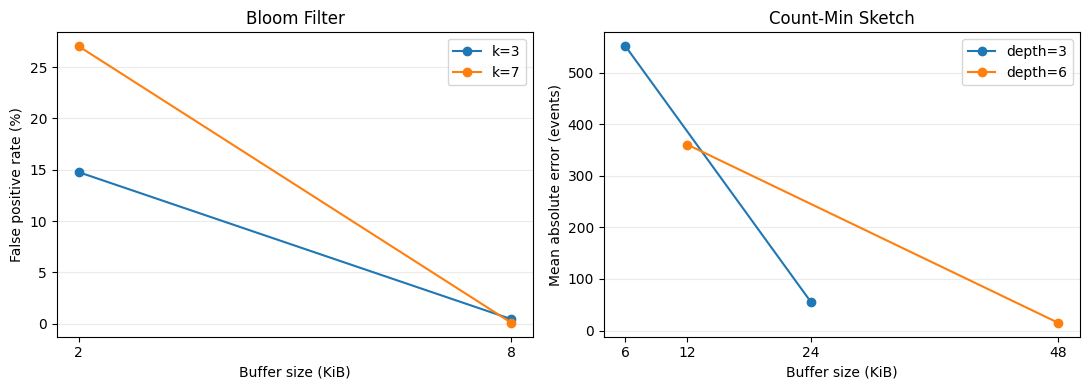

In [10]:
import matplotlib.pyplot as plt
from matplotlib.ticker import NullLocator

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for k, group in bloom.groupby("k"):
    axes[0].plot(group["KiB"], group["FPR (%)"], marker="o", label=f"k={k}")
for depth, group in cms.groupby("depth"):
    axes[1].plot(group["KiB"], group["mae"], marker="o", label=f"depth={depth}")
axes[0].set(title="Bloom Filter", ylabel="False positive rate (%)", xticks=[2, 8])
axes[1].set(title="Count-Min Sketch", ylabel="Mean absolute error (events)", xticks=[6, 12, 24, 48])
for ax in axes:
    ax.set_xlabel("Buffer size (KiB)")
    ax.xaxis.set_minor_locator(NullLocator())
    ax.grid(axis="y", alpha=0.25)
    ax.legend()
fig.tight_layout()
plt.show()